# StarDist2D: Train on Synthetic, Evaluate on Real Microscopy Images

Trains a `StarDist2D` instance-segmentation model on the synthetic particle images/masks produced by
`synthetic_particle_generator_no_flip.ipynb`, then evaluates it two ways:

1. **Synthetic validation set** — full quantitative comparison against ground truth (object-matching
   stats across IoU thresholds, plus pixel-level boundary precision/recall/F1/IoU), since we have exact
   ground truth masks there.
2. **Real microscopy images** — visual overlay of predicted particle boundaries always; quantitative
   metrics too **if** you provide ground-truth masks for a few real images (Section 7 checks for this
   automatically and skips the quantitative part with a clear message if none are found).

This continues directly from `01_data_setup.ipynb` / the synthetic generator notebook — same
`Config2D`/`StarDist2D` setup, just cleaned up and extended with the boundary-level metrics and the
real-image evaluation path.


## 1. Setup

In [5]:
!pip -q install stardist[tf] csbdeep tifffile scikit-image


zsh:1: no matches found: stardist[tf]


In [6]:
from __future__ import print_function, unicode_literals, absolute_import, division
import os, sys, random
import numpy as np
import matplotlib
matplotlib.rcParams["image.interpolation"] = 'none'
import matplotlib.pyplot as plt

from glob import glob
from tqdm import tqdm
from tifffile import imread, imwrite
from PIL import Image

from csbdeep.utils import Path, normalize
from stardist import fill_label_holes, random_label_cmap, calculate_extents, gputools_available
from stardist.models import Config2D, StarDist2D
from stardist.matching import matching_dataset, matching

lbl_cmap = random_label_cmap()

SEED = 42
random.seed(SEED); np.random.seed(SEED)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Colab -- skipping Drive mount. Using local filesystem paths instead.")


Not running in Colab -- skipping Drive mount. Using local filesystem paths instead.


## 2. Config

`SYNTH_DIR` should point at the `dataset/images` / `dataset/masks` output from the synthetic generator
notebook. `REAL_IMAGE_DIR` is your folder of real microscope frames (e.g. containing `1_3.jpg`-style
images). `REAL_MASK_DIR` is optional — leave it as `None` (or an empty/missing folder) if you don't have
ground-truth masks for real images yet; quantitative real-data metrics will just be skipped in that case.


In [7]:
# Synthetic dataset: images and masks
SYNTH_IMAGE_DIR = "/Users/ishaan/Downloads/FINALREPORT/dataset/images"
SYNTH_MASK_DIR  = "/Users/ishaan/Downloads/FINALREPORT/dataset/masks"

# Real microscope images
REAL_IMAGE_DIR = "/Users/ishaan/Downloads/FINALREPORT/images/overlap_images"
REAL_MASK_DIR  = "/Users/ishaan/Downloads/FINALREPORT/real_masks"

# StarDist model settings
MODEL_NAME = "stardist_particle_model"
MODEL_BASEDIR = "/Users/ishaan/Downloads/FINALREPORT/models"  # absolute path -- avoids saving into whatever the cwd happens to be

# --- over-segmentation fix (big particle split into several small ones): back to defaults,
# a finer grid/more rays only made the network more sensitive to internal texture ---
N_RAYS = 64
GRID = (1, 1)   # full resolution so tiny particles are not lost

# --- missed-detection fix (very large particle gets NO boundary at all, see screenshot):
# this happens when the particle is bigger than the network's receptive field ("field of
# view"), so it can't measure distance-to-edge correctly from the center and its confidence
# collapses in the interior. unet_n_depth controls that field of view -- higher = network can
# "see" further out from each pixel, at the cost of more memory/compute. Check the printed
# field-of-view vs median object size in Section 4 after changing this.
UNET_N_DEPTH = 4      # was left at the StarDist default of 3

QUICK_DEMO = False   # set False for full training once the pipeline is verified end-to-end
EPOCHS = 120          # more epochs so the network has time to learn from the extra
                      # scale + merge variation introduced in the augmenter (Section 5)
STEPS_PER_EPOCH = max(100, len(glob(os.path.join(SYNTH_IMAGE_DIR, "*.tif"))) * 4)  # scales with dataset size

IOU_THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


In [8]:
# Sanity check: confirm this notebook's working directory and that the synthetic data actually
# exists at the configured paths, before we try to load it. This catches the "notebook opened from
# a weird temp folder" class of bug early instead of a confusing FileNotFoundError several cells down.
import os
print("Notebook working directory:", os.getcwd())
print("SYNTH_IMAGE_DIR exists:", os.path.isdir(SYNTH_IMAGE_DIR),
      "-- n_files:", len(os.listdir(SYNTH_IMAGE_DIR)) if os.path.isdir(SYNTH_IMAGE_DIR) else 0)
print("SYNTH_MASK_DIR exists: ", os.path.isdir(SYNTH_MASK_DIR),
      "-- n_files:", len(os.listdir(SYNTH_MASK_DIR)) if os.path.isdir(SYNTH_MASK_DIR) else 0)
print("REAL_IMAGE_DIR exists: ", os.path.isdir(REAL_IMAGE_DIR),
      "-- n_files:", len(os.listdir(REAL_IMAGE_DIR)) if os.path.isdir(REAL_IMAGE_DIR) else 0)


Notebook working directory: /Users/ishaan/Downloads/FinalReport
SYNTH_IMAGE_DIR exists: True -- n_files: 500
SYNTH_MASK_DIR exists:  True -- n_files: 500
REAL_IMAGE_DIR exists:  True -- n_files: 101


## 3. Load Synthetic Training Data

In [9]:
X_paths = sorted(glob(os.path.join(SYNTH_IMAGE_DIR, "*.tif")))
Y_paths = sorted(glob(os.path.join(SYNTH_MASK_DIR, "*.tif")))

assert len(X_paths) > 0, f"No synthetic images found in {SYNTH_IMAGE_DIR} -- run the generator notebook first."
assert len(X_paths) == len(Y_paths), "Mismatch between number of images and masks."

X = list(map(imread, X_paths))
Y = list(map(imread, Y_paths))
n_channel = 1 if X[0].ndim == 2 else X[0].shape[-1]
print(f"Loaded {len(X)} synthetic image/mask pairs, n_channel={n_channel}")

axis_norm = (0, 1)
X = [normalize(x, 1, 99.8, axis=axis_norm) for x in tqdm(X, desc="normalizing")]
Y = [fill_label_holes(y) for y in tqdm(Y, desc="filling label holes")]

rng = np.random.RandomState(SEED)
ind = rng.permutation(len(X))
n_val = max(1, int(round(0.15 * len(ind))))
ind_train, ind_val = ind[:-n_val], ind[-n_val:]

X_val, Y_val = [X[i] for i in ind_val], [Y[i] for i in ind_val]
X_trn, Y_trn = [X[i] for i in ind_train], [Y[i] for i in ind_train]

print(f"training:   {len(X_trn)}")
print(f"validation: {len(X_val)}")


Loaded 500 synthetic image/mask pairs, n_channel=1


filling label holes: 100%|██████████| 500/500 [00:00<00:00, 566.45it/s]

training:   425
validation: 75


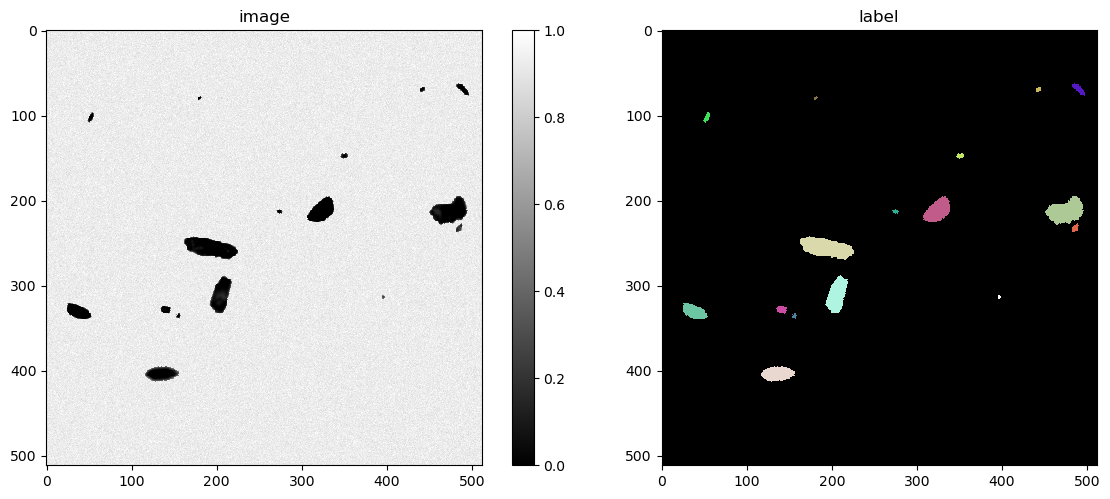

In [10]:
def plot_img_label(img, lbl, img_title="image", lbl_title="label", **kwargs):
    fig, (ai, al) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw=dict(width_ratios=(1.25, 1)))
    im = ai.imshow(img, cmap='gray', clim=(0, 1))
    ai.set_title(img_title); fig.colorbar(im, ax=ai)
    al.imshow(lbl, cmap=lbl_cmap); al.set_title(lbl_title)
    plt.tight_layout()

i = min(3, len(X_trn) - 1)
plot_img_label(X_trn[i], Y_trn[i])


## 4. Model Configuration

In [11]:
# NOTE: this used to read "use_gpu = False and gputools_available()", which is always False
# no matter what gputools_available() returns (Python short-circuits "and" on the first
# False) -- so GPU was silently never used even when available. Fixed to actually detect it.
use_gpu = gputools_available()
print("using GPU:", use_gpu)

conf = Config2D(
    n_rays=N_RAYS,
    grid=GRID,
    use_gpu=use_gpu,
    n_channel_in=n_channel,
    unet_n_depth=UNET_N_DEPTH,   # bigger field of view so large particles are seen whole
)
print(conf)

model = StarDist2D(conf, name=MODEL_NAME, basedir=MODEL_BASEDIR)


using GPU: False
Config2D(n_dim=2, axes='YXC', n_channel_in=1, n_channel_out=65, train_checkpoint='weights_best.h5', train_checkpoint_last='weights_last.h5', train_checkpoint_epoch='weights_now.h5', n_rays=64, grid=(1, 1), backbone='unet', n_classes=None, unet_n_depth=4, unet_kernel_size=(3, 3), unet_n_filter_base=32, unet_n_conv_per_depth=2, unet_pool=(2, 2), unet_activation='relu', unet_last_activation='relu', unet_batch_norm=False, unet_dropout=0.0, unet_expansion=2, unet_prefix='', net_conv_after_unet=128, net_input_shape=(None, None, 1), net_mask_shape=(None, None, 1), train_shape_completion=False, train_completion_crop=32, train_patch_size=(256, 256), train_background_reg=0.0001, train_foreground_only=0.9, train_sample_cache=True, train_dist_loss='mae', train_loss_weights=(1, 0.2), train_class_weights=(1, 1), train_epochs=400, train_steps_per_epoch=100, train_learning_rate=0.0003, train_batch_size=4, train_n_val_patches=None, train_tensorboard=True, train_reduce_lr={'factor': 0.5

base_model.py (203): output path for model already exists, files may be overwritten: /Users/ishaan/Downloads/FINALREPORT/models/stardist_particle_model


In [12]:
# field-of-view sanity check -- warns if particles are larger than what the network can see
median_size = calculate_extents(list(Y), np.median)
fov = np.array(model._axes_tile_overlap('YX'))
print(f"median object size:     {median_size}")
print(f"network field of view:  {fov}")
if any(median_size > fov):
    print("WARNING: median object size larger than the network's field of view -- consider a deeper model or larger grid.")


median object size:     [18. 18.]
network field of view:  [64 64]


## 5. Data Augmentation

`augmenter` now includes `random_scale`, which zooms each training crop in/out (0.6x-1.7x) before every step so the network sees the same particles at many different apparent sizes -- this is the fix for under-segmentation where a whole cluster gets detected as one particle instead of each particle individually. Combined with the finer `GRID=(1,1)` and higher `N_RAYS=48` set in Section 2, the network gets both more training-time size variation and more spatial resolution to actually draw a line between particles that are touching or overlapping.

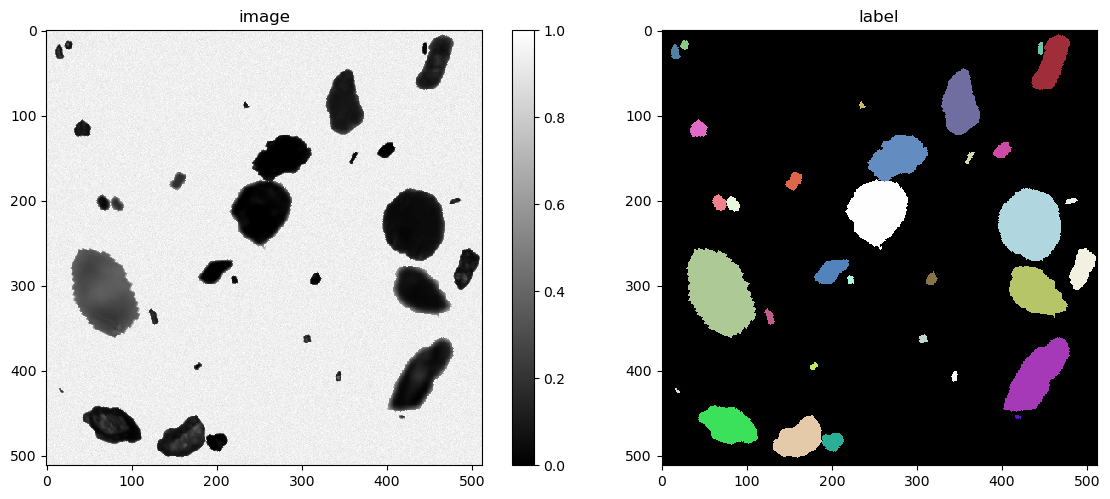

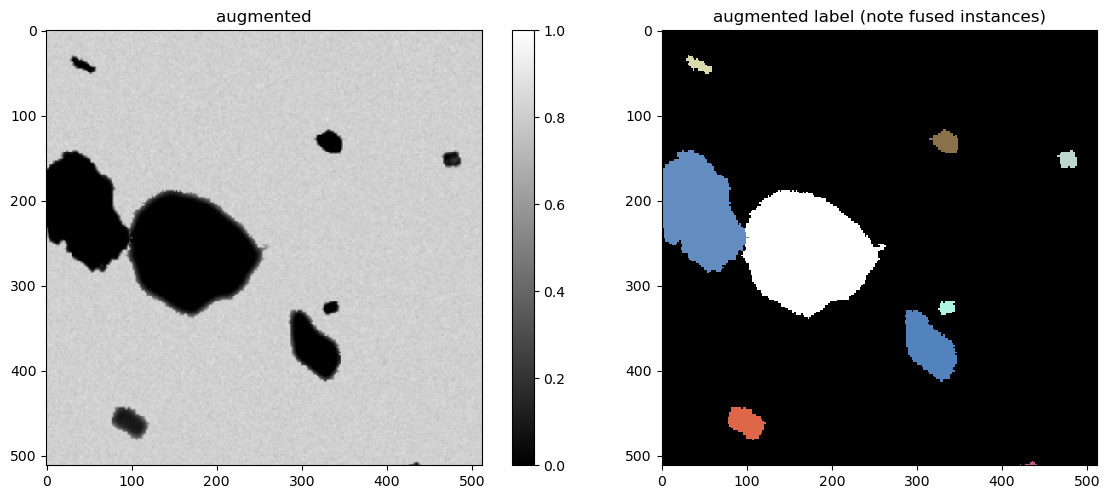

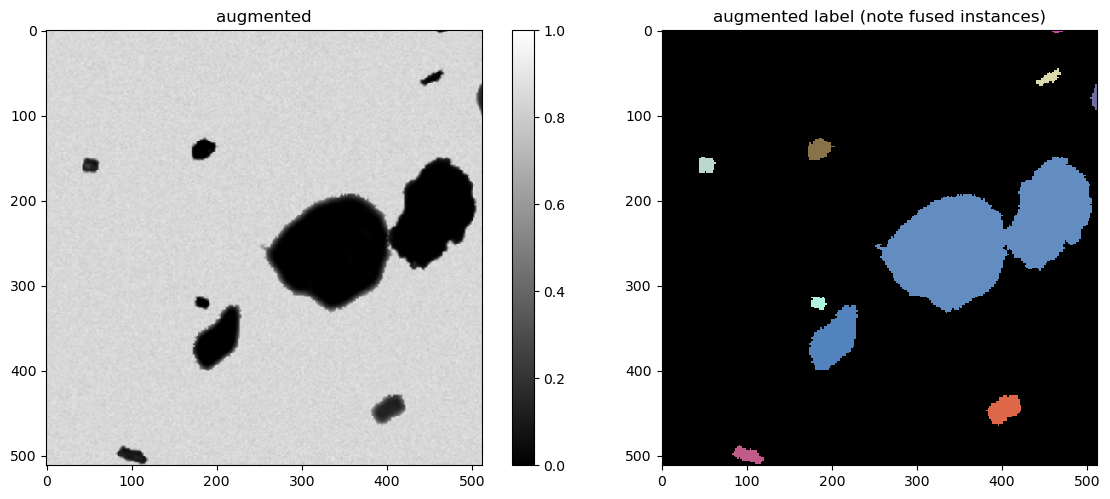

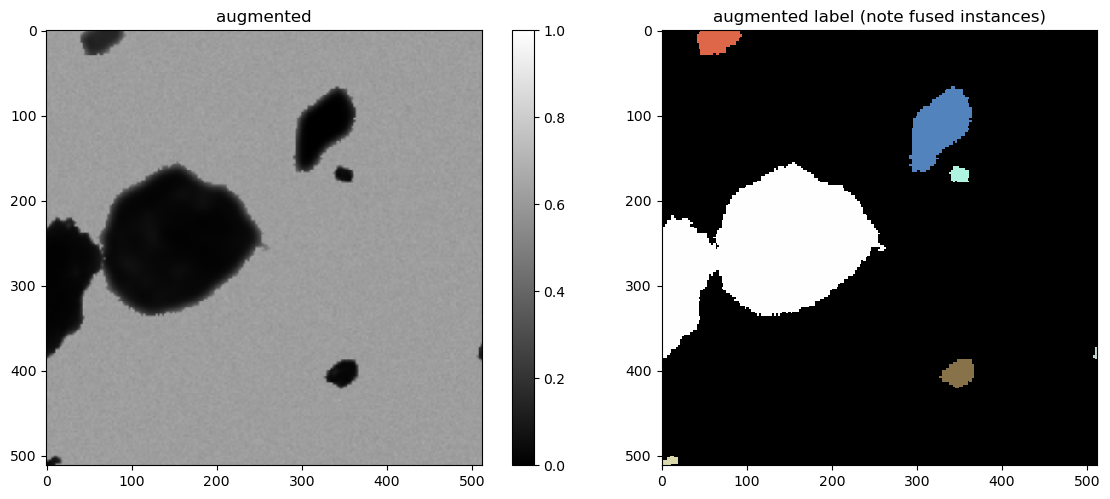

In [13]:
from scipy.ndimage import zoom, binary_dilation

def random_fliprot(img, mask):
    assert img.ndim >= mask.ndim
    axes = tuple(range(mask.ndim))
    perm = tuple(np.random.permutation(axes))
    img = img.transpose(perm + tuple(range(mask.ndim, img.ndim)))
    mask = mask.transpose(perm)
    for ax in axes:
        if np.random.rand() > 0.5:
            img = np.flip(img, axis=ax)
            mask = np.flip(mask, axis=ax)
    return img, mask

def random_intensity_change(img):
    img = img * np.random.uniform(0.6, 1.4) + np.random.uniform(-0.1, 0.1)
    return img

def random_scale(img, mask, scale_range=(0.4, 2.5)):
    """Randomly zoom the training crop in/out before each step, so the network sees the
    same particles at many different apparent sizes -- tiny and separated one step, large
    and dense the next. Upper end pushed to 2.0x so it practices on genuinely LARGE
    particles more often, not just small ones."""
    s = np.random.uniform(*scale_range)
    if abs(s - 1.0) < 1e-3:
        return img, mask
    h, w = mask.shape[:2]
    img_zoom = zoom(img, (s, s) + (1,) * (img.ndim - 2), order=1)
    mask_zoom = zoom(mask, (s, s), order=0)   # nearest-neighbour -- never interpolate label ids

    def fit_to(arr, target_h, target_w):
        ah, aw = arr.shape[:2]
        if ah > target_h:
            top = (ah - target_h) // 2
            arr = arr[top:top + target_h]
        if aw > target_w:
            left = (aw - target_w) // 2
            arr = arr[:, left:left + target_w]
        ah, aw = arr.shape[:2]
        pad_h, pad_w = max(0, target_h - ah), max(0, target_w - aw)
        if pad_h or pad_w:
            pad_width = [(pad_h // 2, pad_h - pad_h // 2), (pad_w // 2, pad_w - pad_w // 2)]
            pad_width += [(0, 0)] * (arr.ndim - 2)
            arr = np.pad(arr, pad_width, mode='constant', constant_values=0)
        return arr

    img_zoom = fit_to(img_zoom, h, w)
    mask_zoom = fit_to(mask_zoom, h, w)
    return img_zoom, mask_zoom

def random_merge_nearby_instances(mask, merge_prob=0.5, max_merges=3, dilation_iters=3):
    """THE fix for 'one big particle gets predicted as 4-5 small ones': the synthetic
    generator's ground truth only ever contains small individual particles, so the network
    has never once been trained on a label that says 'this whole big irregular clump is
    ONE object'. This randomly fuses a few touching/adjacent instances in the training mask
    into a single instance id, so the network also learns that pattern -- not just
    'clusters of touching things are always separate objects'.
    Only merges instances that are actually close together (touching after a small
    dilation), never distant ones, so it isn't teaching nonsense merges.
    """
    mask = mask.copy()
    ids = [i for i in np.unique(mask) if i != 0]
    if len(ids) < 2 or np.random.rand() > merge_prob:
        return mask
    np.random.shuffle(ids)
    n_merges = np.random.randint(1, max_merges + 1)
    merged = 0
    used = set()
    for i in ids:
        if merged >= n_merges:
            break
        if i in used:
            continue
        dil_i = binary_dilation(mask == i, iterations=dilation_iters)
        neighbours = [n for n in np.unique(mask[dil_i]) if n not in (0, i) and n not in used]
        if neighbours:
            j = np.random.choice(neighbours)
            mask[mask == j] = i   # fuse j into i -> now a single, larger instance
            used.add(i); used.add(j)
            merged += 1
    return mask

def augmenter(x, y):
    x, y = random_fliprot(x, y)
    x, y = random_scale(x, y)
    y = random_merge_nearby_instances(y)
    x = random_intensity_change(x)
    return x, y

img, lbl = X_trn[0], Y_trn[0]
plot_img_label(img, lbl)
for _ in range(3):
    img_aug, lbl_aug = augmenter(img, lbl)
    plot_img_label(img_aug, lbl_aug, img_title="augmented", lbl_title="augmented label (note fused instances)")


## 6. Train

Leave `QUICK_DEMO = True` the first time through to confirm the whole pipeline runs, then flip it to
`False` and re-run this cell for a real training run.


In [14]:
# Time a small number of steps before committing to a full run -- CPU-only training (common on Mac
# without tensorflow-metal configured) can be dramatically slower than GPU, so this tells us whether
# EPOCHS=60/STEPS_PER_EPOCH=50 is a five-minute job or a multi-hour one before we start it for real.
# NOTE: this actually trains for 1 epoch (the weights carry over into the cell below), it's not a
# no-op timer -- skip re-running this cell if you're re-executing the notebook and already know the timing.
import time
t0 = time.time()
model.train(X_trn, Y_trn, validation_data=(X_val, Y_val), augmenter=augmenter,
            epochs=1, steps_per_epoch=20)
elapsed = time.time() - t0
print(f"1 epoch (20 steps) took {elapsed:.1f}s -- est. full run ({EPOCHS} epochs x {STEPS_PER_EPOCH} steps): "
      f"{elapsed / 20 * EPOCHS * STEPS_PER_EPOCH / 60:.1f} min")


20/20 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - dist_dist_iou_metric: 0.0039 - dist_loss: 28.2563 - dist_relevant_mae: 28.2562 - dist_relevant_mse: 1386.2118 - loss: 6.1821 - prob_kld: 0.4832 - prob_loss: 0.5309 - val_dist_dist_iou_metric: 0.0109 - val_dist_loss: 20.5729 - val_dist_relevant_mae: 20.5289 - val_dist_relevant_mse: 685.6679 - val_loss: 4.2942 - val_prob_kld: 0.1369 - val_prob_loss: 0.1881 - learning_rate: 3.0000e-04

Loading network weights from 'weights_best.h5'.
1 epoch (20 steps) took 39.5s -- est. full run (120 epochs x 2000 steps): 7898.7 min


In [15]:
# Watch the loss curve rather than trusting a fixed epoch count -- if val_loss is still dropping,
# train longer; if it has flattened or starts rising while train_loss keeps falling, more epochs
# won't help (and rising val_loss with only ~100 synthetic images is a real overfitting risk worth
# addressing by generating more synthetic data rather than training longer).
history = model.history if hasattr(model, "history") else None
if history is not None and hasattr(history, "history") and "loss" in history.history:
    plt.figure(figsize=(6, 4))
    plt.plot(history.history["loss"], label="train loss")
    if "val_loss" in history.history:
        plt.plot(history.history["val_loss"], label="val loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
    plt.title("Training loss curve")
    plt.tight_layout(); plt.show()
else:
    print("No training history available on `model` -- re-run the training cell and check the returned object.")


No training history available on `model` -- re-run the training cell and check the returned object.


In [16]:
# if QUICK_DEMO:
#     print("NOTE: QUICK_DEMO=True -- short run just to validate the pipeline (still uses the\n"
#           "      new multi-scale augmenter, but for far fewer steps than a real run needs).\n"
#           "      Set QUICK_DEMO=False and rerun this cell for a full training run.", file=sys.stderr)
#     history = model.train(X_trn, Y_trn, validation_data=(X_val, Y_val), augmenter=augmenter,
#                            epochs=100, steps_per_epoch=30)
# else:
#     history = model.train(X_trn, Y_trn, validation_data=(X_val, Y_val), augmenter=augmenter,
#                            epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH)

import time

EPOCHS = 50
STEPS_PER_EPOCH = 20

start_time = time.time()

history = model.train(
    X_trn,
    Y_trn,
    validation_data=(X_val, Y_val),
    augmenter=augmenter,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH
)

elapsed = (time.time() - start_time) / 60
print(f"Total training time: {elapsed:.1f} minutes")

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - dist_dist_iou_metric: 0.0700 - dist_loss: 23.1043 - dist_relevant_mae: 23.1037 - dist_relevant_mse: 1016.8461 - loss: 4.8841 - prob_kld: 0.2279 - prob_loss: 0.2633 - val_dist_dist_iou_metric: 0.1793 - val_dist_loss: 30.2990 - val_dist_relevant_mae: 30.2758 - val_dist_relevant_mse: 1561.5505 - val_loss: 6.6717 - val_prob_kld: 0.5607 - val_prob_loss: 0.6140 - learning_rate: 3.0000e-04
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - dist_dist_iou_metric: 0.1058 - dist_loss: 27.5416 - dist_relevant_mae: 27.5400 - dist_relevant_mse: 1395.5004 - loss: 6.0690 - prob_kld: 0.4989 - prob_loss: 0.5607 - val_dist_dist_iou_metric: 0.1922 - val_dist_loss: 14.4178 - val_dist_relevant_mae: 14.4406 - val_dist_relevant_mse: 414.2359 - val_loss: 3.4988 - val_prob_kld: 0.5555 - val_prob_loss: 0.6088 - learning_rate: 3.0000e-04
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - dist_dist_iou_metric: 0.0654 - dist_loss: 21.7056 - dist_relevant_mae: 21

In [17]:
# Always optimize on the FULL validation set, not a slice of it -- prob_thresh/nms_thresh
# decide how aggressively nearby detections get merged vs kept separate.
model.optimize_thresholds(X_val, Y_val)
print("optimized thresholds:", model.thresholds)


NMS threshold = 0.5:  75%|███████▌  | 15/20 [05:11<01:43, 20.73s/it, 0.587 -> 0.392]


Using optimized values: prob_thresh=0.557732, nms_thresh=0.3.
Saving to 'thresholds.json'.
optimized thresholds: Thresholds(prob=0.5577321003448685, nms=0.3)


### 6b. Manual threshold nudge (only needed if problems persist after retraining)

Two independent knobs, for two independent symptoms:

- **`nms_thresh` down** -> more merging -> fixes a big particle still getting split into several detections.
- **`prob_thresh` down** -> more (lower-confidence) detections get kept -> fixes a large/faint particle being missed entirely, like the one with no boundary at all in the screenshot. Don't lower it too far or you'll start picking up background noise as particles -- check visually after each change.

Prefer re-running `optimize_thresholds` after retraining with the Section 4/5 changes first; only hand-tune if it's still off.

In [18]:
# Uncomment and tune as needed:
# current = model.thresholds
# model.thresholds = current._replace(nms=max(0.1, current.nms - 0.1),
#                                      prob=max(0.05, current.prob - 0.1))
# print("manually adjusted thresholds:", model.thresholds)


## 7. Evaluate on Synthetic Validation Set (full ground truth available)

Two complementary views of "detect particles and boundaries, compare to ground truth":

- **Object-level matching** (StarDist's own metrics): precision/recall/F1/accuracy/panoptic quality as a
  function of IoU threshold — tells you how well whole particles are detected and separated.
- **Pixel-level boundary metrics**: precision/recall/F1/IoU computed directly on the boundary pixels
  (derived from instance IDs) — tells you specifically how well the *edges* line up, independent of
  whether the object-matching threshold counts a detection as a hit or miss.


In [19]:
Y_val_pred = [model.predict_instances(x, n_tiles=model._guess_n_tiles(x), show_tile_progress=False)[0]
              for x in tqdm(X_val, desc="predicting")]


predicting: 100%|██████████| 75/75 [01:07<00:00,  1.11it/s]


In [20]:
# Quick sanity check before trusting the boundary-overlay plots below: if pred instance counts are
# 0 across the board, the model hasn't learned to detect anything yet (classic QUICK_DEMO symptom --
# too few training steps) rather than a plotting bug.
for i in range(min(3, len(Y_val))):
    n_gt = len(np.unique(Y_val[i])) - 1
    n_pred = len(np.unique(Y_val_pred[i])) - 1
    print(f"val[{i}]: GT instances={n_gt}, Pred instances={n_pred}")


val[0]: GT instances=29, Pred instances=35
val[1]: GT instances=42, Pred instances=36
val[2]: GT instances=40, Pred instances=35


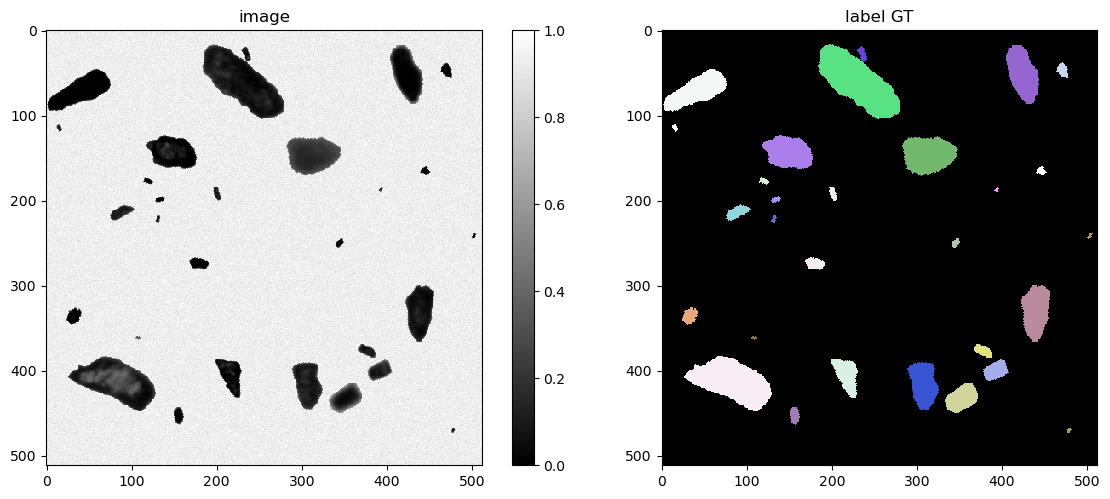

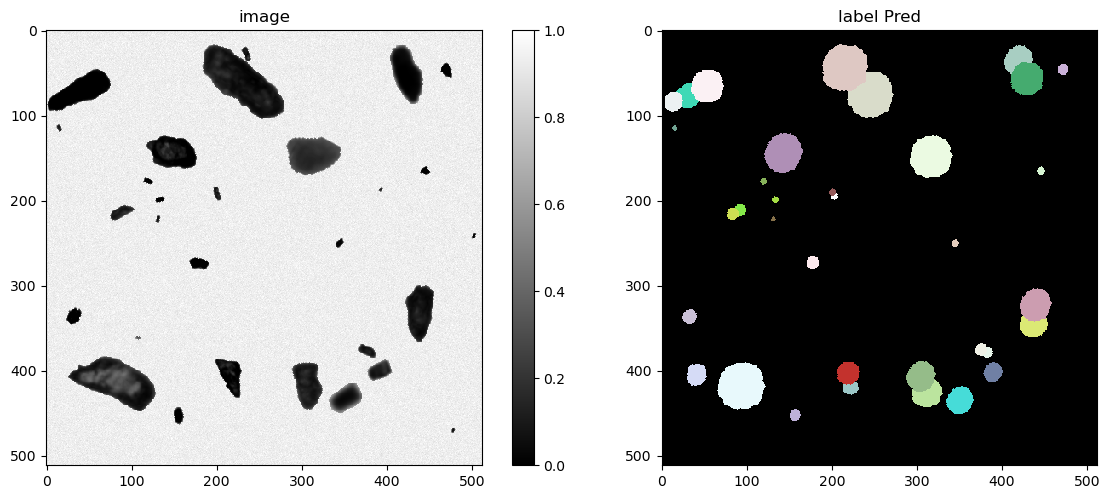

In [21]:
plot_img_label(X_val[0], Y_val[0], lbl_title="label GT")
plot_img_label(X_val[0], Y_val_pred[0], lbl_title="label Pred")


In [22]:
stats = [matching_dataset(Y_val, Y_val_pred, thresh=t, show_progress=False) for t in tqdm(IOU_THRESHOLDS, desc="matching")]

print(f"Matching statistics at IoU threshold tau=0.5:")
print(stats[IOU_THRESHOLDS.index(0.5)])


matching: 100%|██████████| 9/9 [00:02<00:00,  3.64it/s]

Matching statistics at IoU threshold tau=0.5:
DatasetMatching(criterion='iou', thresh=0.5, fp=850, tp=1576, fn=813, precision=0.6496290189612531, recall=0.6596902469652575, accuracy=0.48656992899042917, f1=0.6546209761163032, n_true=2389, n_pred=2426, mean_true_score=0.4465192219561341, mean_matched_score=0.6768619424195459, panoptic_quality=0.4430880254426602, by_image=False)


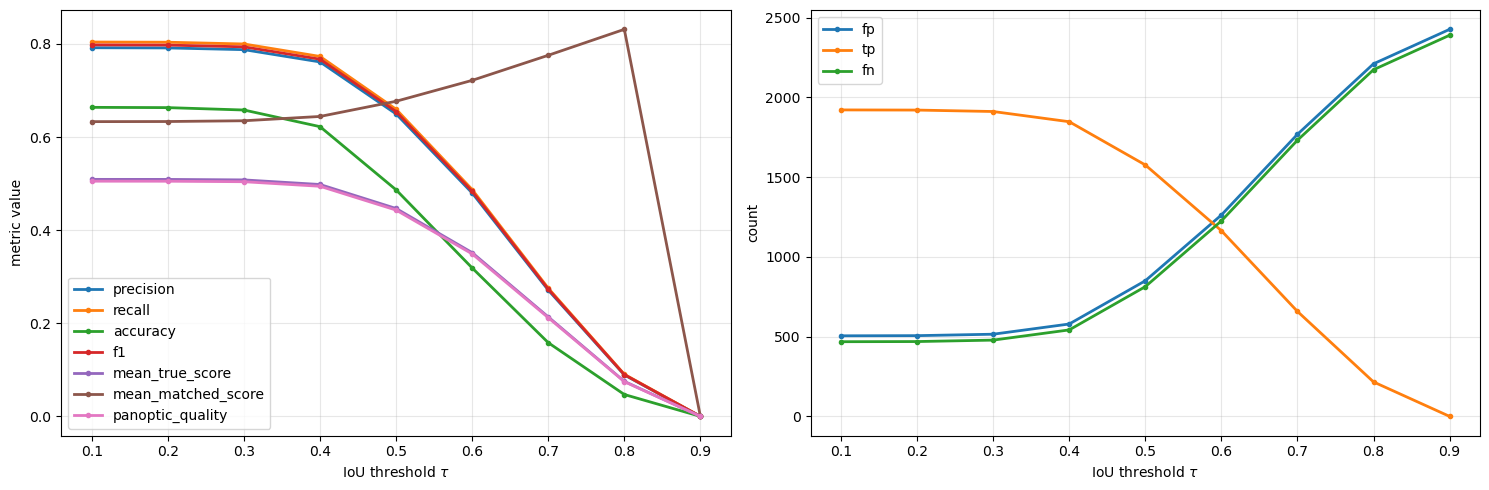

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for m in ('precision', 'recall', 'accuracy', 'f1', 'mean_true_score', 'mean_matched_score', 'panoptic_quality'):
    ax1.plot(IOU_THRESHOLDS, [s._asdict()[m] for s in stats], '.-', lw=2, label=m)
ax1.set_xlabel(r'IoU threshold $\tau$'); ax1.set_ylabel('metric value')
ax1.grid(alpha=0.3); ax1.legend()

for m in ('fp', 'tp', 'fn'):
    ax2.plot(IOU_THRESHOLDS, [s._asdict()[m] for s in stats], '.-', lw=2, label=m)
ax2.set_xlabel(r'IoU threshold $\tau$'); ax2.set_ylabel('count')
ax2.grid(alpha=0.3); ax2.legend()

plt.tight_layout(); plt.show()


In [24]:
def boundary_from_instance_mask(inst_mask, thickness=1):
    """1px boundary wherever a pixel touches a different instance id (including background)."""
    boundary = np.zeros_like(inst_mask, dtype=np.float32)
    for shift in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        shifted = np.roll(inst_mask, shift, axis=(0, 1))
        boundary = np.maximum(boundary, (shifted != inst_mask).astype(np.float32))
    boundary[0, :] = boundary[-1, :] = boundary[:, 0] = boundary[:, -1] = 0
    if thickness > 1:
        from skimage import morphology
        boundary = morphology.dilation(boundary, morphology.disk(thickness // 2))
    return boundary


def boundary_prf1_iou(pred_inst, gt_inst, thickness=1, tolerance=1):
    """Boundary precision/recall/F1/IoU, with a small tolerance radius (in px) since boundary
    localization rarely lines up to the exact pixel even for a good detection."""
    from skimage import morphology
    pred_b = boundary_from_instance_mask(pred_inst, thickness) > 0
    gt_b = boundary_from_instance_mask(gt_inst, thickness) > 0

    if tolerance > 0:
        gt_b_dilated = morphology.dilation(gt_b, morphology.disk(tolerance))
        pred_b_dilated = morphology.dilation(pred_b, morphology.disk(tolerance))
    else:
        gt_b_dilated, pred_b_dilated = gt_b, pred_b

    tp = np.sum(pred_b & gt_b_dilated)
    fp = np.sum(pred_b & ~gt_b_dilated)
    fn = np.sum(gt_b & ~pred_b_dilated)

    eps = 1e-6
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    iou = tp / (tp + fp + fn + eps)
    return {"precision": precision, "recall": recall, "f1": f1, "iou": iou}


boundary_results = [boundary_prf1_iou(pred, gt) for pred, gt in zip(Y_val_pred, Y_val)]
mean_boundary = {k: float(np.mean([r[k] for r in boundary_results])) for k in boundary_results[0]}
print("Mean pixel-level boundary metrics on synthetic validation set (tolerance=1px):")
for k, v in mean_boundary.items():
    print(f"  {k}: {v:.4f}")


Mean pixel-level boundary metrics on synthetic validation set (tolerance=1px):
  precision: 0.4943
  recall: 0.4451
  f1: 0.4681
  iou: 0.3066


Generated predictions for 3 validation images.


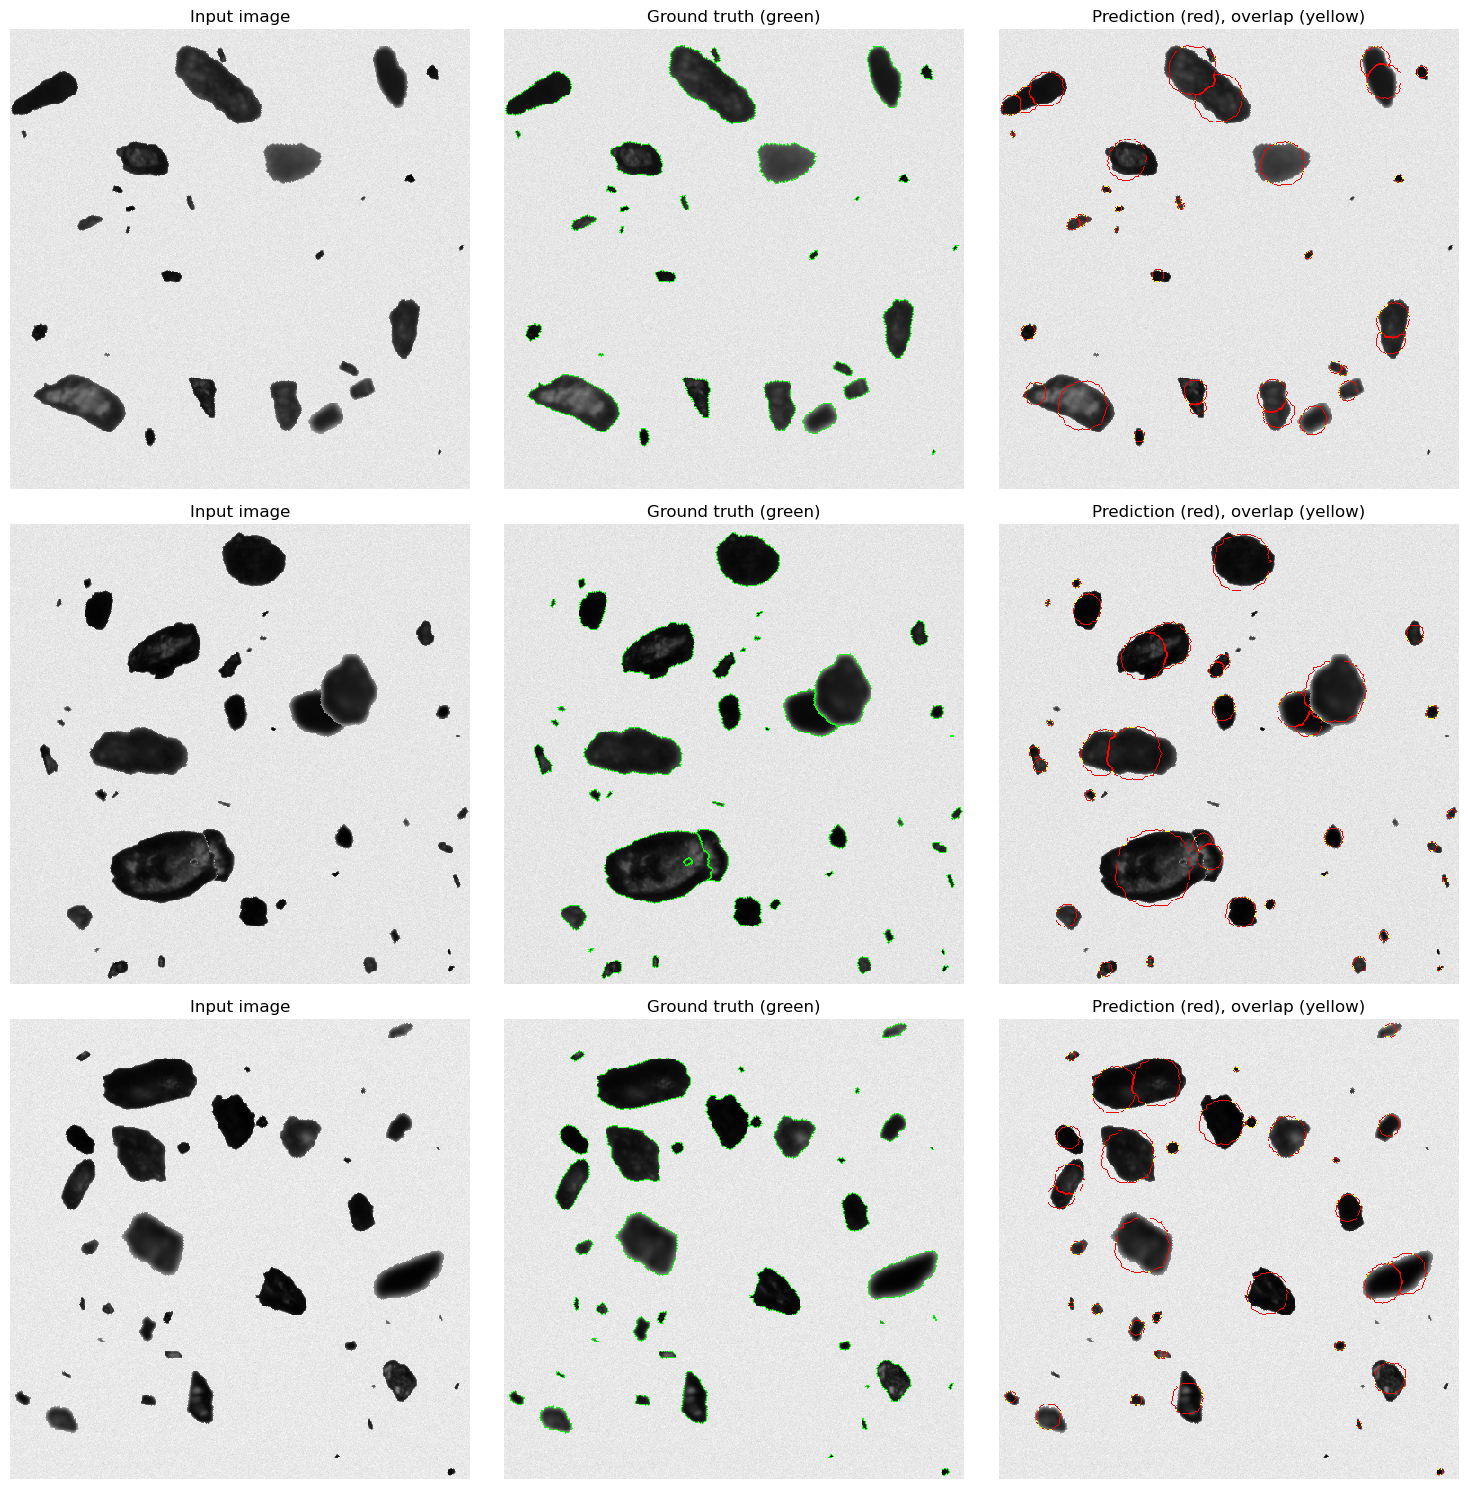

In [25]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_erosion

# --------------------------------------------------
# 1. Extract boundaries from instance segmentation masks
# --------------------------------------------------
def boundary_from_instance_mask(mask):
    mask = np.asarray(mask).squeeze()

    if mask.ndim != 2:
        raise ValueError(
            f"Expected a 2D mask, but got shape {mask.shape}"
        )

    boundaries = np.zeros(mask.shape, dtype=bool)

    for label_id in np.unique(mask):
        if label_id == 0:
            continue

        particle = mask == label_id
        eroded = binary_erosion(particle)
        boundaries |= particle & ~eroded

    return boundaries


# --------------------------------------------------
# 2. Generate predictions for validation images
# --------------------------------------------------
n_show = min(3, len(X_val), len(Y_val))

Y_val_pred = []

for i in range(n_show):
    img = np.asarray(X_val[i]).squeeze()

    # StarDist returns (instance_label_mask, details)
    pred_mask, _ = model.predict_instances(img)
    Y_val_pred.append(pred_mask)

print(f"Generated predictions for {n_show} validation images.")


# --------------------------------------------------
# 3. Visualize input, ground truth, and predictions
# --------------------------------------------------
fig, axes = plt.subplots(
    n_show, 3, figsize=(15, 5 * n_show), squeeze=False
)

for row in range(n_show):
    img = np.asarray(X_val[row]).squeeze()
    gt_mask = np.asarray(Y_val[row]).squeeze()
    pred_mask = np.asarray(Y_val_pred[row]).squeeze()

    if img.shape != gt_mask.shape or img.shape != pred_mask.shape:
        raise ValueError(
            f"Shape mismatch at sample {row}: "
            f"image={img.shape}, GT={gt_mask.shape}, "
            f"prediction={pred_mask.shape}"
        )

    gt_b = boundary_from_instance_mask(gt_mask)
    pred_b = boundary_from_instance_mask(pred_mask)

    # Normalize image for RGB overlays
    img_float = img.astype(np.float32)
    img_float -= img_float.min()
    if img_float.max() > 0:
        img_float /= img_float.max()

    rgb_base = np.repeat(img_float[..., None], 3, axis=-1)

    # Input image
    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title("Input image")
    axes[row, 0].axis("off")

    # Ground truth: green boundaries
    overlay_gt = rgb_base.copy()
    overlay_gt[gt_b] = [0, 1, 0]

    axes[row, 1].imshow(overlay_gt)
    axes[row, 1].set_title("Ground truth (green)")
    axes[row, 1].axis("off")

    # Prediction: red; overlap with GT: yellow
    overlay_pred = rgb_base.copy()
    overlay_pred[pred_b] = [1, 0, 0]
    overlay_pred[gt_b & pred_b] = [1, 1, 0]

    axes[row, 2].imshow(overlay_pred)
    axes[row, 2].set_title("Prediction (red), overlap (yellow)")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()




## 7b. Polygon Outputs (native StarDist representation)

StarDist predicts polygons directly (radial distances at `N_RAYS` angles), then rasterizes them into the label image used above. Pulling out `details['coord']` exposes the actual polygon vertices, which matters for anything downstream that wants vector shapes (area, perimeter, convexity) rather than a pixel grid, and is also the "polygon-based boundary" output requested for comparison.


Extracted 35 polygons, 64 vertices each (N_RAYS=64)


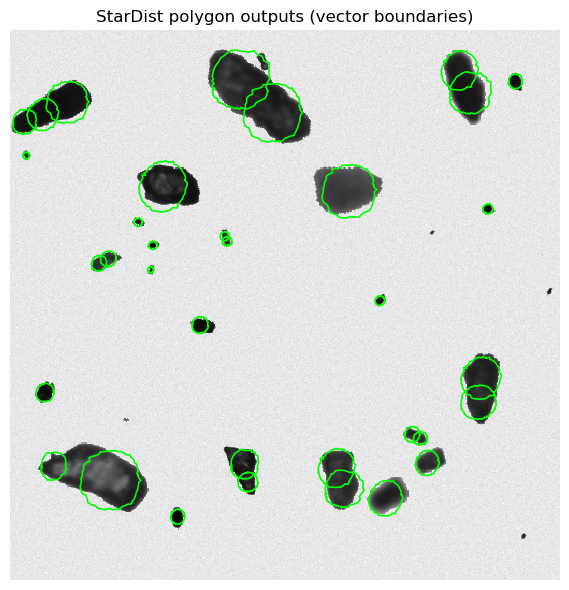

In [26]:
# StarDist predicts polygons directly, not just a rasterized mask. Pulling out details['coord']
# lets us inspect the actual polygon vertices, which matters for anything downstream that wants
# vector shapes (area, perimeter, convexity) rather than a pixel grid.
idx_poly = 0
img_poly = X_val[idx_poly]
labels_poly, details_poly = model.predict_instances(img_poly, n_tiles=model._guess_n_tiles(img_poly))

coords = details_poly['coord']   # shape: (n_objects, 2, n_rays) -- (y, x) vertices per object
print(f"Extracted {coords.shape[0]} polygons, {coords.shape[2]} vertices each (N_RAYS={N_RAYS})")

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.imshow(img_poly, cmap="gray")
for obj_coord in coords:
    yy, xx = obj_coord[0], obj_coord[1]
    ax.plot(np.append(xx, xx[0]), np.append(yy, yy[0]), '-', lw=1.2, color='lime')
ax.set_title("StarDist polygon outputs (vector boundaries)")
ax.axis("off")
plt.tight_layout(); plt.show()


## 7c. Distance-Transform & Watershed Baseline

Distance-transform + watershed is the classic way to split touching blobs: the distance-to-background map is treated as a landscape where each particle's centre is a peak, and regions are flooded outward from each peak until they meet. This works well for convex, near-circular particles, but irregular/non-convex particles often have multiple local peaks *within one particle* (over-segmentation) or peaks that merge across touching particles (under-segmentation). This section shows that failure mode directly, then quantifies the gap against StarDist across the whole validation set.


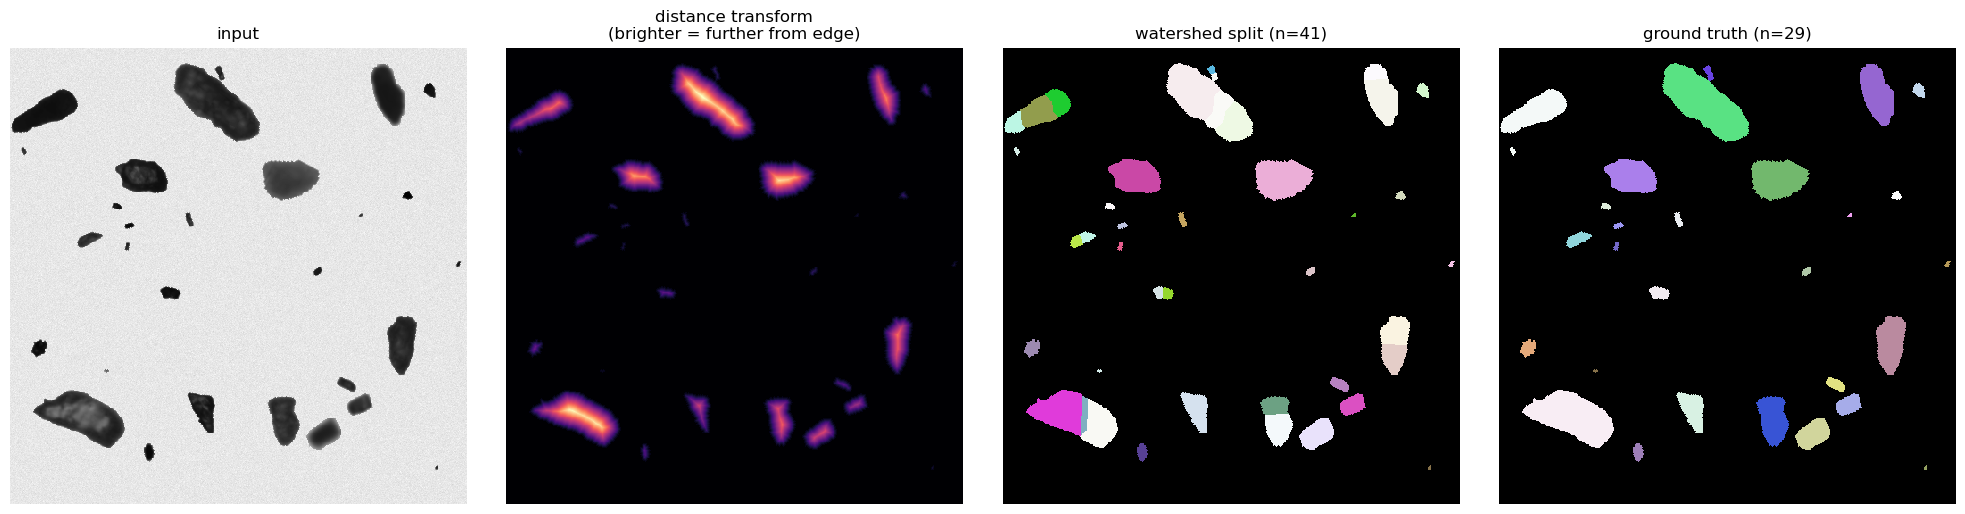

Watershed found 41 objects vs 29 ground truth.
A mismatch here is exactly the over/under-segmentation failure mode on non-convex shapes.


In [27]:
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

def watershed_baseline(binary_mask, min_distance=5):
    """Classic distance-transform + watershed instance splitting."""
    distance = ndi.distance_transform_edt(binary_mask)
    coords = peak_local_max(distance, min_distance=min_distance, labels=binary_mask)
    peak_mask = np.zeros_like(distance, dtype=bool)
    peak_mask[tuple(coords.T)] = True
    markers, _ = ndi.label(peak_mask)
    return watershed(-distance, markers, mask=binary_mask), distance

idx_ws = 0
gt_mask = Y_val[idx_ws]
binary_gt = gt_mask > 0   # GT foreground -- isolates the splitting problem specifically,
                          # since watershed here doesn't also have to detect particles from raw pixels
labels_ws, distance_map = watershed_baseline(binary_gt)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(X_val[idx_ws], cmap="gray"); axes[0].set_title("input"); axes[0].axis("off")
axes[1].imshow(distance_map, cmap="magma"); axes[1].set_title("distance transform\n(brighter = further from edge)"); axes[1].axis("off")
axes[2].imshow(labels_ws, cmap=lbl_cmap); axes[2].set_title(f"watershed split (n={labels_ws.max()})"); axes[2].axis("off")
axes[3].imshow(gt_mask, cmap=lbl_cmap); axes[3].set_title(f"ground truth (n={gt_mask.max()})"); axes[3].axis("off")
plt.tight_layout(); plt.show()

print(f"Watershed found {labels_ws.max()} objects vs {len(np.unique(gt_mask)) - 1} ground truth.")
print("A mismatch here is exactly the over/under-segmentation failure mode on non-convex shapes.")


In [28]:
# Quantitative comparison across the full validation set. Watershed still gets GT-foreground input
# (so it's only solving splitting), while StarDist solves detection+splitting from the raw image --
# this isolates whether StarDist's advantage is really about handling non-convex shapes, not just
# being a better detector overall.
Y_val_ws = [watershed_baseline(y > 0)[0] for y in Y_val]

ws_stats_05 = matching_dataset(Y_val, Y_val_ws, thresh=0.5, show_progress=False)
sd_stats_05 = stats[IOU_THRESHOLDS.index(0.5)]

print("Object-level comparison at IoU=0.5 (val set):")
print(f"  Watershed baseline : f1={ws_stats_05.f1:.4f}  panoptic_quality={ws_stats_05.panoptic_quality:.4f}")
print(f"  StarDist            : f1={sd_stats_05.f1:.4f}  panoptic_quality={sd_stats_05.panoptic_quality:.4f}")


Object-level comparison at IoU=0.5 (val set):
  Watershed baseline : f1=0.8403  panoptic_quality=0.7714
  StarDist            : f1=0.6546  panoptic_quality=0.4431


## 8. Evaluate on Real Microscopy Images

Always shows the predicted boundaries overlaid on the real image. If `REAL_MASK_DIR` exists and contains
matching mask files, it also runs the same quantitative metrics as Section 7 on the real data — this is
the actual sim-to-real gap check. If there are no real masks yet, this section tells you so explicitly
and just gives you the visual output; quantitative real-data metrics require you to (or a tool you use)
annotate ground truth for at least a handful of real frames.


In [29]:
real_image_paths = sorted(glob(os.path.join(REAL_IMAGE_DIR, "*.jpg")) +
                           glob(os.path.join(REAL_IMAGE_DIR, "*.png")) +
                           glob(os.path.join(REAL_IMAGE_DIR, "*.tif")) +
                           glob(os.path.join(REAL_IMAGE_DIR, "*.bmp")))
print(f"Found {len(real_image_paths)} real images in {REAL_IMAGE_DIR}")

real_masks_available = os.path.isdir(REAL_MASK_DIR) and len(glob(os.path.join(REAL_MASK_DIR, "*"))) > 0
print(f"Real ground-truth masks available: {real_masks_available}")
if not real_masks_available:
    print("  -> No masks found in REAL_MASK_DIR. Quantitative metrics on real data will be skipped;\n"
          "     only visual predictions will be shown. Add ground-truth masks (same filename stem\n"
          "     as the image) to REAL_MASK_DIR to enable quantitative real-data evaluation.")


Found 100 real images in /Users/ishaan/Downloads/FINALREPORT/images/overlap_images
Real ground-truth masks available: False
  -> No masks found in REAL_MASK_DIR. Quantitative metrics on real data will be skipped;
     only visual predictions will be shown. Add ground-truth masks (same filename stem
     as the image) to REAL_MASK_DIR to enable quantitative real-data evaluation.


In [30]:
# ---- Boundary refinement (v3): StarDist = detection / instance IDs, threshold + watershed = outline ----
# StarDist can only output star-convex (roughly circular) polygons. So we use it ONLY to find and
# separate particles (seeds), then let each seed flood out to the real thresholded particle shape.
# v2 grew labels by a fixed 4px, which could never recover irregular outlines -- this removes that limit.
from skimage.segmentation import expand_labels, watershed
from skimage.filters import threshold_otsu, gaussian
from skimage.measure import label as cc_label
from scipy import ndimage as ndi

THRESH_OFFSET = 0.0    # negative = stricter/tighter (try -0.05 to -0.1 if the blur halo gets included)
SMOOTH_SIGMA  = 1.0    # px, light blur before thresholding so noise doesn't make ragged edges
CAP           = 20     # px, max distance a label may flood beyond its StarDist polygon (leak guard)
MIN_AREA      = 6      # px, drop tiny specks
REFINE_MODE   = "watershed"   # "watershed": keeps touching particles separate (distance-transform split)
                              # "component" : one object per connected dark blob (merges duplicate circles
                              #               on one big particle, but also merges genuinely touching ones)

def load_real_raw(path):
    return np.array(Image.open(path).convert("L")).astype(np.float32) / 255.0

def foreground_mask(img_gray01, thr=None):
    smooth = gaussian(img_gray01, SMOOTH_SIGMA)
    thr = (threshold_otsu(smooth) if thr is None else thr) + THRESH_OFFSET
    return ndi.binary_fill_holes(smooth < thr)          # dark particle pixels

def refine_labels(img_gray01, labels, thr=None, mode=None, cap=CAP, min_area=MIN_AREA):
    mode = mode or REFINE_MODE
    fg = foreground_mask(img_gray01, thr)
    seeds = labels * fg                                  # StarDist ids restricted to real particle pixels
    allowed = expand_labels(labels, distance=cap) > 0    # label may not leak far past its own detection

    if mode == "component":
        comps = cc_label(fg & allowed, connectivity=2)
        out = np.zeros_like(labels)
        for c in np.unique(comps[seeds > 0]):
            if c == 0:
                continue
            ids, counts = np.unique(seeds[comps == c], return_counts=True)
            keep = ids != 0
            if keep.any():
                out[comps == c] = ids[keep][np.argmax(counts[keep])]
    else:
        dist = ndi.distance_transform_edt(fg)
        out = watershed(-dist, markers=seeds, mask=fg & allowed)

    # drop specks
    for l in np.unique(out):
        if l != 0 and (out == l).sum() < min_area:
            out[out == l] = 0
    return out

def refine_path(path, labels):
    return refine_labels(load_real_raw(path), labels)


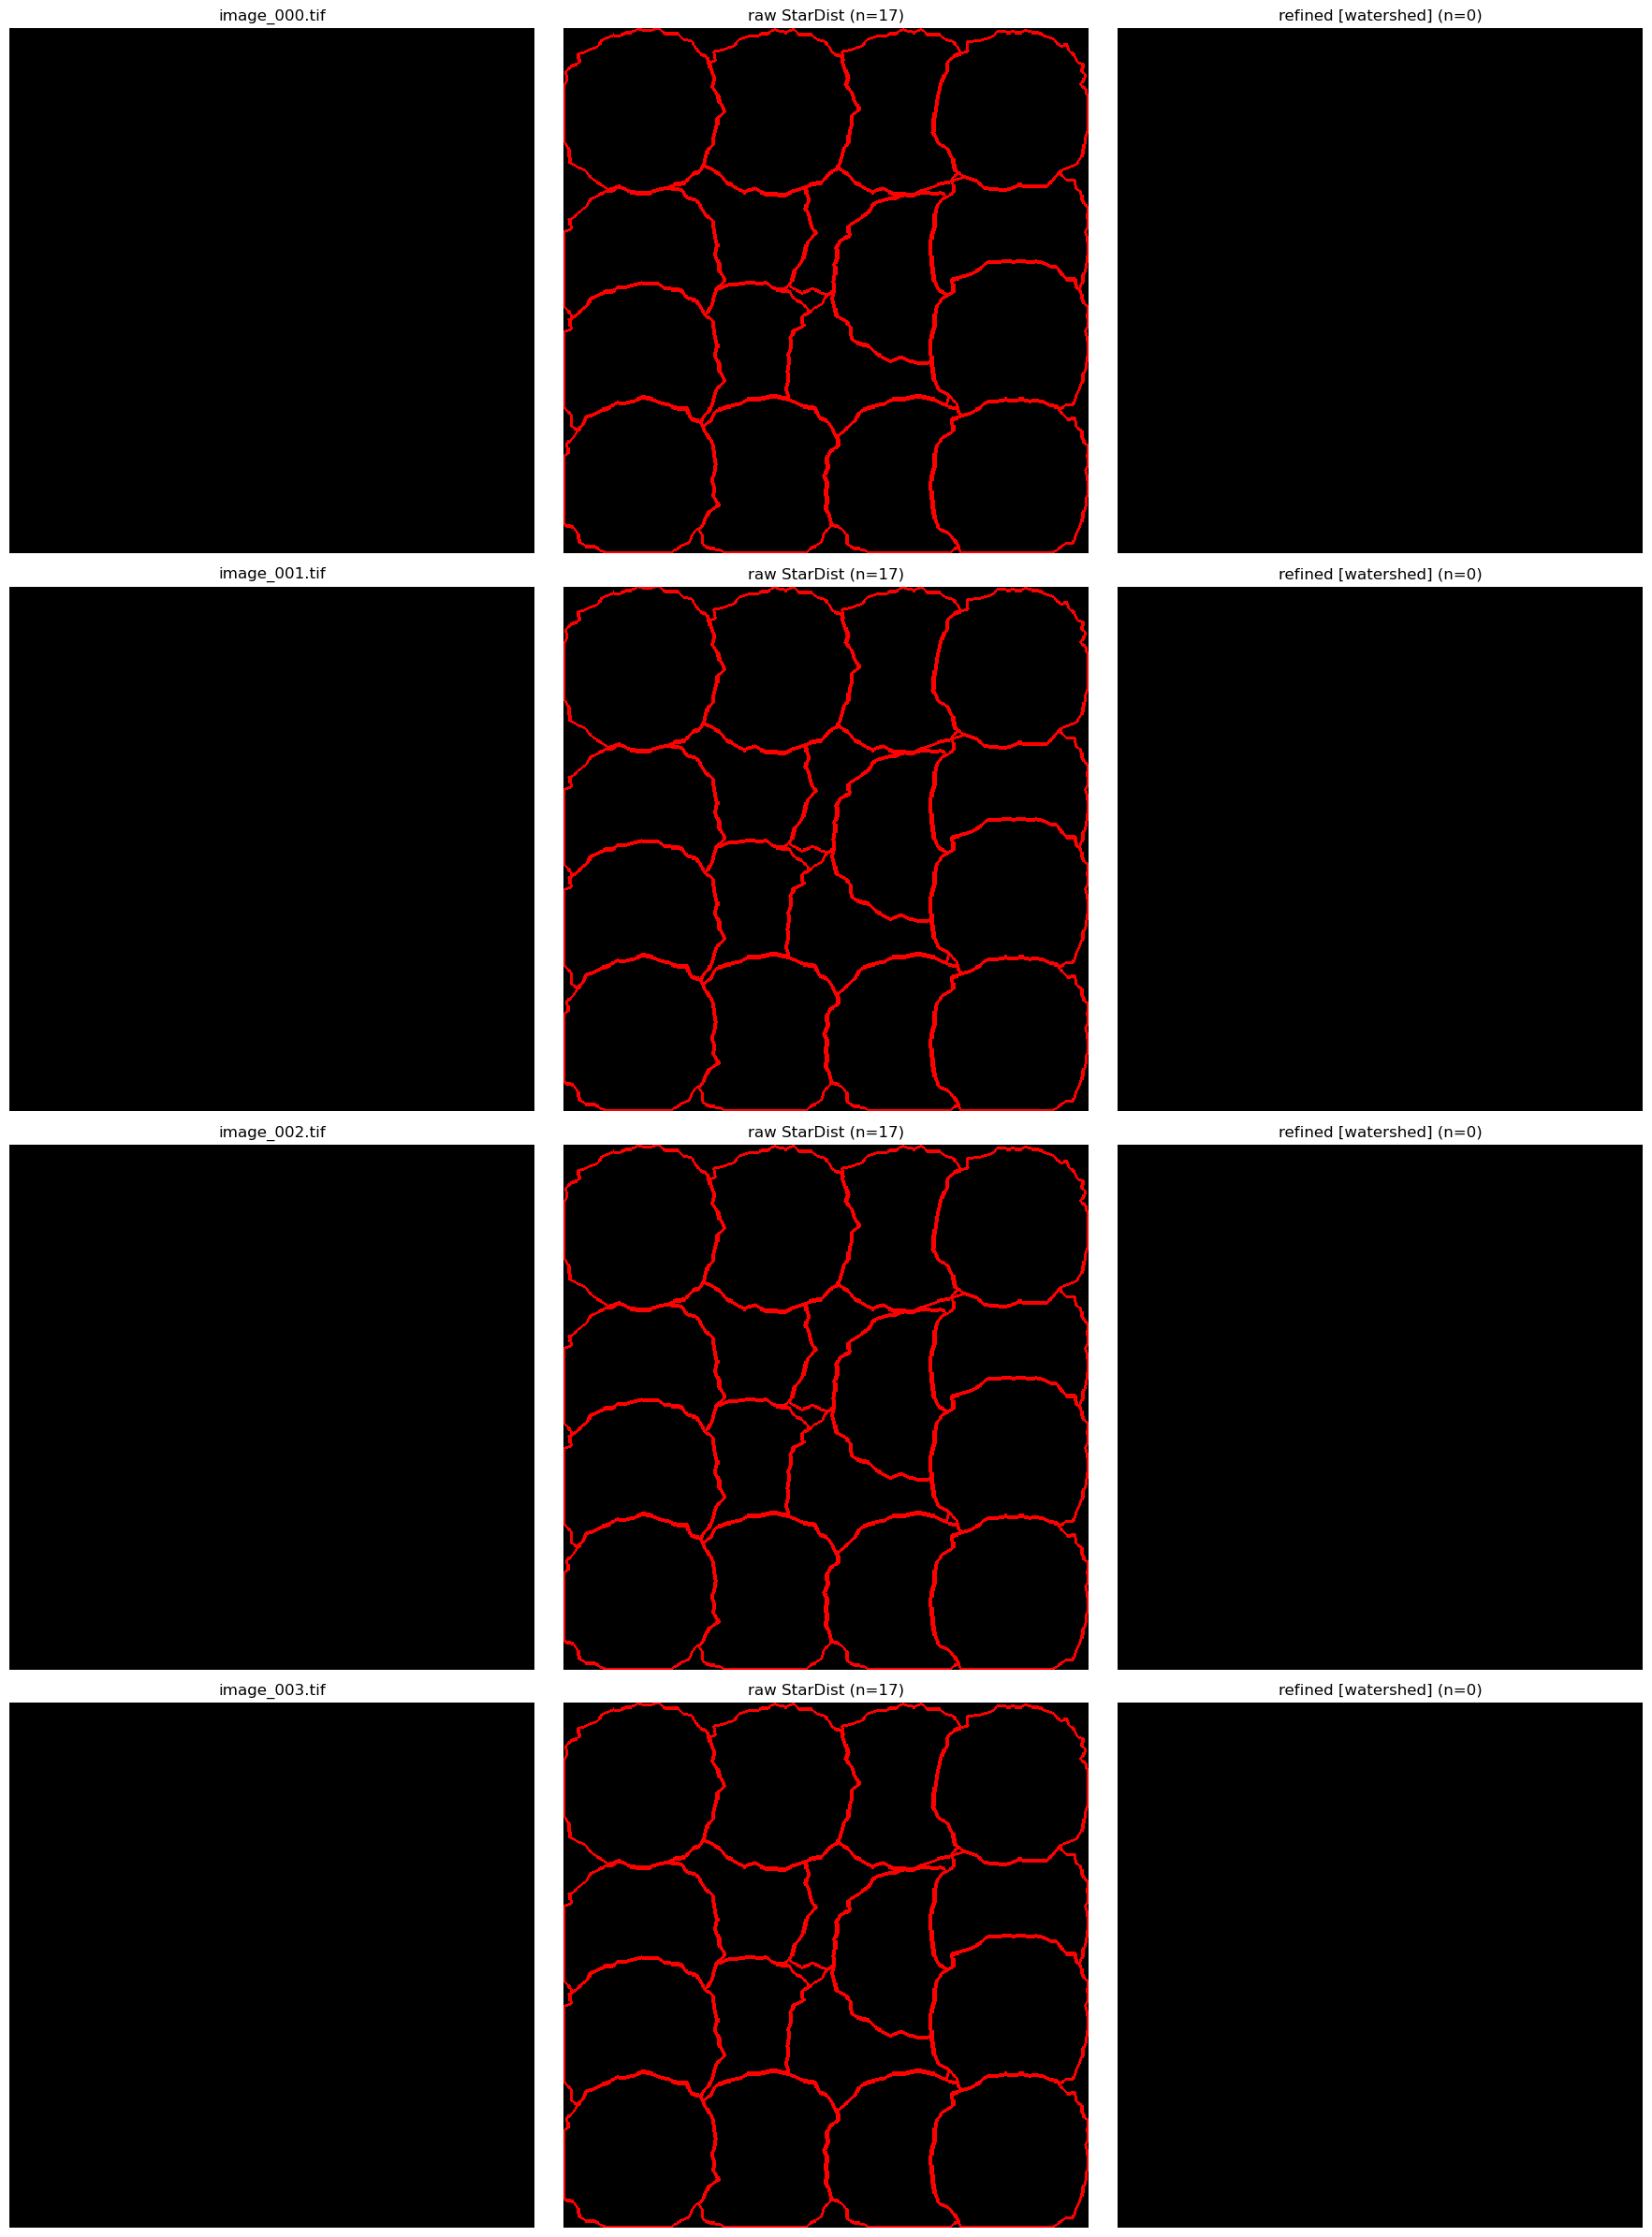

In [31]:
def load_real_image(path):
    img = np.array(Image.open(path).convert("L")).astype(np.float32) / 255.0
    return normalize(img, 1, 99.8)

from scipy.ndimage import binary_dilation

def overlay_boundaries(gray01, labels, color=(1, 0, 0)):
    """Draw instance outlines ~2px thick so they are actually visible."""
    b = binary_dilation(boundary_from_instance_mask(labels) > 0, iterations=1)
    rgb = np.stack([np.clip(gray01, 0, 1)] * 3, axis=-1)
    rgb[b] = color
    return rgb

# Before/after: raw image | raw StarDist (star-convex polygons) | refined (threshold + watershed)
# Tip: to look at specific images, e.g. 10_43.jpg and 10_44.jpg, set WANTED below.
WANTED = ["10_43.jpg", "10_44.jpg"]
paths = [p for p in real_image_paths if os.path.basename(p) in WANTED] or real_image_paths[:min(4, len(real_image_paths))]

if len(paths) == 0:
    print("No real images found -- check REAL_IMAGE_DIR.")
else:
    fig, axes = plt.subplots(len(paths), 3, figsize=(18, 6 * len(paths)), squeeze=False)
    for row, path in enumerate(paths):
        real_img = load_real_image(path)
        raw_gray = load_real_raw(path)
        raw_labels, details = model.predict_instances(real_img, n_tiles=model._guess_n_tiles(real_img))
        refined = refine_labels(raw_gray, raw_labels)

        axes[row, 0].imshow(raw_gray, cmap="gray"); axes[row, 0].set_title(os.path.basename(path))
        axes[row, 1].imshow(overlay_boundaries(raw_gray, raw_labels));  axes[row, 1].set_title(f"raw StarDist (n={len(np.unique(raw_labels)) - 1})")
        axes[row, 2].imshow(overlay_boundaries(raw_gray, refined));     axes[row, 2].set_title(f"refined [{REFINE_MODE}] (n={len(np.unique(refined)) - 1})")
        for a in axes[row]:
            a.axis("off")
    plt.tight_layout(); plt.show()


### 8c. Threshold Sweep -- compare several nms_thresh / prob_thresh combos side by side

Instead of hand-editing Section 6b one value at a time and rerunning the overlay separately for
each guess, this predicts the SAME real image(s) at a small grid of threshold combos around your
current `model.thresholds`, and shows every result at once with its detected object count. Look
for the combo where genuinely single particles stop reading as 2 without real touching pairs
starting to merge into 1 -- pick it by eye, then set it permanently with the Section 6b cell.

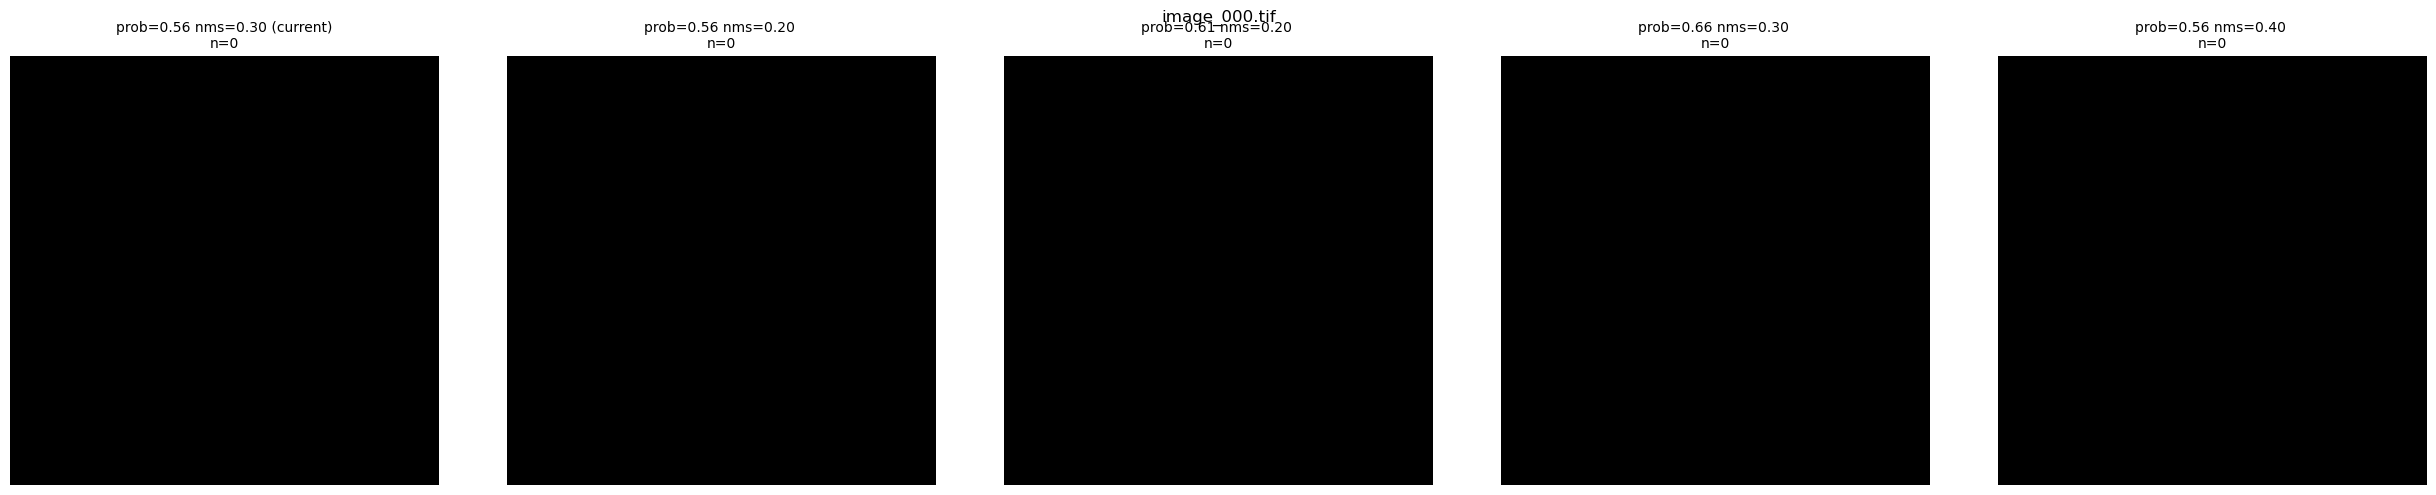

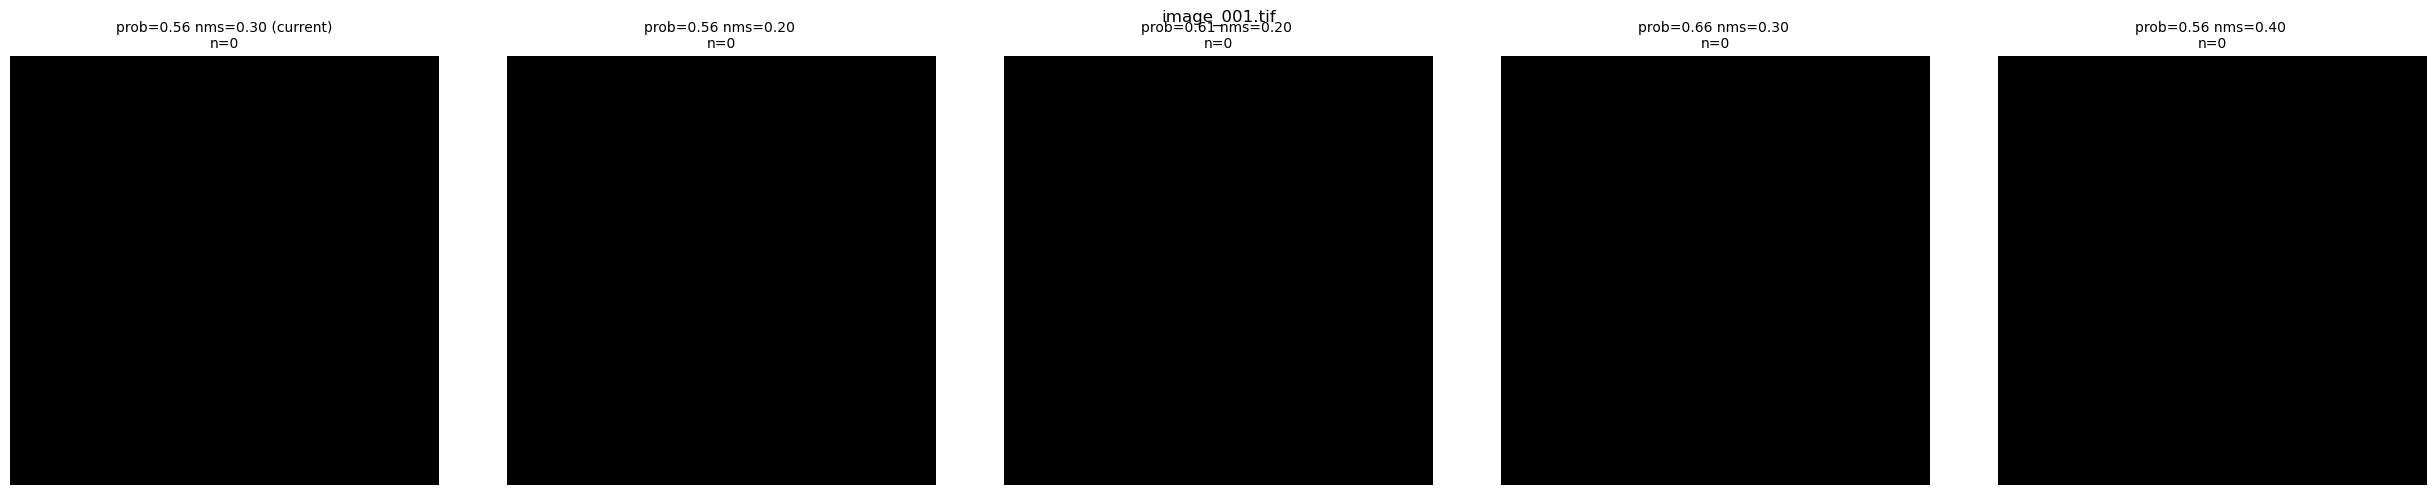

Once you find the best combo above, set it permanently in Section 6b, e.g.:
  current = model.thresholds
  model.thresholds = current._replace(prob=<your pick>, nms=<your pick>)


In [32]:
SWEEP_IMAGE_INDICES = list(range(min(2, len(real_image_paths))))   # which real images to sweep over

base_prob = model.thresholds.prob
base_nms = model.thresholds.nms

# (delta_prob, delta_nms) offsets from your current optimized thresholds -- clipped to [0.05, 0.95]
SWEEP_DELTAS = [(0.0, 0.0), (0.0, -0.1), (0.05, -0.1), (0.1, 0.0), (0.0, 0.1)]

def clip01(v, lo=0.05, hi=0.95):
    return max(lo, min(hi, v))

for idx in SWEEP_IMAGE_INDICES:
    real_img = load_real_image(real_image_paths[idx])
    n_combos = len(SWEEP_DELTAS)
    fig, axes = plt.subplots(1, n_combos, figsize=(5 * n_combos, 5))
    if n_combos == 1:
        axes = [axes]
    for ax, (dp, dn) in zip(axes, SWEEP_DELTAS):
        p = clip01(base_prob + dp)
        n = clip01(base_nms + dn)
        pred_labels, _ = model.predict_instances(real_img, n_tiles=model._guess_n_tiles(real_img),
                                                   prob_thresh=p, nms_thresh=n)
        pred_labels = refine_path(real_image_paths[idx], pred_labels)
        pred_b = boundary_from_instance_mask(pred_labels) > 0
        overlay = np.stack([real_img] * 3, axis=-1)
        overlay[pred_b] = [1, 0, 0]
        count = len(np.unique(pred_labels)) - 1
        tag = "(current)" if (dp, dn) == (0.0, 0.0) else ""
        ax.imshow(overlay)
        ax.set_title(f"prob={p:.2f} nms={n:.2f} {tag}\nn={count}", fontsize=10)
        ax.axis("off")
    fig.suptitle(os.path.basename(real_image_paths[idx]))
    plt.tight_layout(); plt.show()

print("Once you find the best combo above, set it permanently in Section 6b, e.g.:")
print("  current = model.thresholds")
print("  model.thresholds = current._replace(prob=<your pick>, nms=<your pick>)")


### 8b. Bootstrap a REAL_MASK_DIR from the model's own predictions

Annotating real particles from a blank image is slow. It's much faster to let the current
model make a first guess on each real image, then hand-correct only its mistakes (split a
merged blob, delete a false positive, draw in a missed particle) rather than drawing every
particle from scratch. This cell writes one starting-point label mask per real image, named
to match the image filename -- open the output folder in napari / QuPath / Labkit (Fiji),
correct each one, save the corrections back into the same files, then point `REAL_MASK_DIR`
at this folder and rerun Section 8.

In [ ]:
BOOTSTRAP_MASK_DIR = os.path.join(os.path.dirname(REAL_IMAGE_DIR), "real_masks_bootstrap")
os.makedirs(BOOTSTRAP_MASK_DIR, exist_ok=True)

for img_path in real_image_paths:
    stem = os.path.splitext(os.path.basename(img_path))[0]
    real_img = load_real_image(img_path)
    pred_labels, _ = model.predict_instances(real_img, n_tiles=model._guess_n_tiles(real_img))
    pred_labels = refine_path(img_path, pred_labels)
    imwrite(os.path.join(BOOTSTRAP_MASK_DIR, f"{stem}.tif"), pred_labels.astype(np.uint16))

print(f"Wrote {len(real_image_paths)} starting-point label masks to:\n  {BOOTSTRAP_MASK_DIR}")
print("\nNext: open that folder in napari/QuPath/Labkit, correct each mask by hand, save in place.")
print("Then set REAL_MASK_DIR to this same path (or wherever you save the corrected copies) and")
print("rerun Section 8 for real quantitative numbers instead of just the visual overlay.")


## 8b. Structured Qualitative Evaluation (real images, no GT)

Without ground truth we can't compute precision/recall, but unstructured eyeballing doesn't scale past a couple of images and isn't reproducible between people. This gives every real image the same fixed checklist -- meant to be filled in by hand (or swapped for a labeling tool later), not a pretend automatic metric.


In [ ]:
import pandas as pd

qual_records = []
for path in real_image_paths:
    real_img = load_real_image(path)
    pred_labels, _ = model.predict_instances(real_img, n_tiles=model._guess_n_tiles(real_img))
    pred_labels = refine_path(path, pred_labels)
    qual_records.append({
        "image": os.path.basename(path),
        "n_detected": int(len(np.unique(pred_labels)) - 1),
        "oversegmentation_suspected": "",   # y/n -- one particle split into several labels
        "undersegmentation_suspected": "",  # y/n -- overlapping particles merged into one label
        "boundary_quality_1to5": "",        # subjective rating
        "notes": "",
    })

qual_df = pd.DataFrame(qual_records)
qual_df.to_csv("real_image_qualitative_eval.csv", index=False)
print(f"Wrote qualitative checklist for {len(qual_df)} real images to real_image_qualitative_eval.csv")
qual_df


100%|██████████| 24/24 [00:05<00:00,  4.58it/s]

Wrote qualitative checklist for 46 real images to real_image_qualitative_eval.csv


,image,n_detected,oversegmentation_suspected,undersegmentation_suspected,boundary_quality_1to5,notes
0,10_41.jpg,86,,,,
1,10_42.jpg,115,,,,
2,10_43.jpg,152,,,,
3,10_44.jpg,137,,,,
4,11_41.jpg,113,,,,
5,11_42.jpg,103,,,,
6,11_43.jpg,108,,,,
7,11_44.jpg,107,,,,
8,12_40.jpg,99,,,,
9,12_41.jpg,77,,,,


In [ ]:
if real_masks_available:
    real_mask_paths = {os.path.splitext(os.path.basename(p))[0]: p
                        for p in glob(os.path.join(REAL_MASK_DIR, "*"))}

    real_pred_list, real_gt_list = [], []
    for img_path in real_image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0]
        if stem not in real_mask_paths:
            continue
        real_img = load_real_image(img_path)
        gt_mask = imread(real_mask_paths[stem]) if real_mask_paths[stem].lower().endswith(('.tif', '.tiff')) \
            else np.array(Image.open(real_mask_paths[stem]))
        pred_labels, _ = model.predict_instances(real_img, n_tiles=model._guess_n_tiles(real_img))
        pred_labels = refine_path(img_path, pred_labels)

        real_pred_list.append(pred_labels)
        real_gt_list.append(gt_mask)

    print(f"Matched {len(real_pred_list)} real image/mask pairs for quantitative evaluation.")

    if len(real_pred_list) > 0:
        real_stats = [matching_dataset(real_gt_list, real_pred_list, thresh=t, show_progress=False) for t in IOU_THRESHOLDS]
        print(f"\nObject-matching stats at IoU threshold tau=0.5 (REAL data):")
        print(real_stats[IOU_THRESHOLDS.index(0.5)])

        real_boundary_results = [boundary_prf1_iou(pred, gt) for pred, gt in zip(real_pred_list, real_gt_list)]
        mean_real_boundary = {k: float(np.mean([r[k] for r in real_boundary_results])) for k in real_boundary_results[0]}
        print("\nMean pixel-level boundary metrics on REAL data (tolerance=1px):")
        for k, v in mean_real_boundary.items():
            print(f"  {k}: {v:.4f}")

        fig, ax = plt.subplots(1, 1, figsize=(7, 5))
        for m in ('precision', 'recall', 'f1', 'panoptic_quality'):
            ax.plot(IOU_THRESHOLDS, [s._asdict()[m] for s in real_stats], '.-', lw=2, label=m)
        ax.set_xlabel(r'IoU threshold $\tau$'); ax.set_ylabel('metric value')
        ax.set_title('Object-matching metrics on REAL data')
        ax.grid(alpha=0.3); ax.legend()
        plt.tight_layout(); plt.show()
else:
    print("Skipping quantitative real-data evaluation -- no ground-truth masks found in REAL_MASK_DIR.")


Skipping quantitative real-data evaluation -- no ground-truth masks found in REAL_MASK_DIR.


## 9. Sim-to-Real Gap Summary

Once Section 8 has run with real ground truth available, compare the printed metrics here:

| | Synthetic val | Real data |
|---|---|---|
| Object F1 @ IoU=0.5 | from Section 7 | from Section 8 |
| Boundary F1 (1px tol.) | from Section 7 | from Section 8 |

A large drop from synthetic to real is the sim-to-real gap — revisit the ring-light/interface-softening
settings in the generator notebook and regenerate training data if the gap is large, then retrain here.


In [ ]:
print("Synthetic validation (Section 7):")
print(f"  object F1 @ tau=0.5:  {stats[IOU_THRESHOLDS.index(0.5)]._asdict()['f1']:.4f}")
print(f"  boundary F1 (1px):    {mean_boundary['f1']:.4f}")

if real_masks_available and 'real_stats' in dir():
    print("\nReal data (Section 8):")
    print(f"  object F1 @ tau=0.5:  {real_stats[IOU_THRESHOLDS.index(0.5)]._asdict()['f1']:.4f}")
    print(f"  boundary F1 (1px):    {mean_real_boundary['f1']:.4f}")
else:
    print("\nReal data: no ground truth available yet -- add masks to REAL_MASK_DIR to fill this in.")


Synthetic validation (Section 7):
  object F1 @ tau=0.5:  0.7900
  boundary F1 (1px):    0.5334

Real data: no ground truth available yet -- add masks to REAL_MASK_DIR to fill this in.


## 10. Save Model

In [ ]:
# StarDist2D already checkpoints during training under MODEL_BASEDIR/MODEL_NAME.
# This just confirms the location and exports thresholds/config alongside weights.
print(f"Model saved under: {os.path.join(MODEL_BASEDIR, MODEL_NAME)}")
print("Contents:", os.listdir(os.path.join(MODEL_BASEDIR, MODEL_NAME)))


Model saved under: /Users/ishaan/Downloads/Clean Dataset 2/models/stardist_particle_model
Contents: ['.DS_Store', 'config.json', 'thresholds.json', 'logs', 'weights_best.h5', 'weights_last.h5']


## 11. Save & Export Results

Metrics and inline plots vanish when the Colab runtime resets. Anything meant for a report, a labeling tool, or a colleague to review needs actual files on disk: predicted masks, boundary overlays, and polygon overlays for both the validation set and the real images.


In [ ]:
import os
EXPORT_DIR = "results_export"
os.makedirs(os.path.join(EXPORT_DIR, "masks"), exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "boundary_overlays"), exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "polygon_overlays"), exist_ok=True)

def save_overlay(img, boundary_mask, path, color=(1, 0, 0)):
    overlay = np.stack([img] * 3, axis=-1)
    overlay[boundary_mask] = color
    plt.imsave(path, overlay)

def save_polygon_overlay(img, coords, path):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img, cmap="gray")
    for obj_coord in coords:
        yy, xx = obj_coord[0], obj_coord[1]
        ax.plot(np.append(xx, xx[0]), np.append(yy, yy[0]), '-', lw=1.2, color='lime')
    ax.axis("off")
    fig.savefig(path, bbox_inches="tight", pad_inches=0)
    plt.close(fig)

# --- validation set ---
for i, (img, pred_mask) in enumerate(zip(X_val, Y_val_pred)):
    stem = f"val_{i:03d}"
    imwrite(os.path.join(EXPORT_DIR, "masks", f"{stem}_mask.tif"), pred_mask.astype(np.uint16))
    b = boundary_from_instance_mask(pred_mask) > 0
    save_overlay(img, b, os.path.join(EXPORT_DIR, "boundary_overlays", f"{stem}_boundary.png"))

# --- real images ---
for path in real_image_paths:
    stem = os.path.splitext(os.path.basename(path))[0]
    real_img = load_real_image(path)
    pred_labels, details = model.predict_instances(real_img, n_tiles=model._guess_n_tiles(real_img))
    pred_labels = refine_path(path, pred_labels)
    imwrite(os.path.join(EXPORT_DIR, "masks", f"real_{stem}_mask.tif"), pred_labels.astype(np.uint16))
    b = boundary_from_instance_mask(pred_labels) > 0
    save_overlay(real_img, b, os.path.join(EXPORT_DIR, "boundary_overlays", f"real_{stem}_boundary.png"))
    save_polygon_overlay(real_img, details['coord'], os.path.join(EXPORT_DIR, "polygon_overlays", f"real_{stem}_polygons.png"))

print(f"Exported masks, boundary overlays, and polygon overlays to ./{EXPORT_DIR}/")


ValueError: Floating point image RGB values must be in the 0..1 range.